# Лабораторная работа №8

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
plt.rcParams['figure.figsize'] = (13, 6)
plt.rcParams['font.size'] = 11

In [3]:
emissions_data = pd.read_csv('owid-co2-data.csv')

In [4]:
print(emissions_data.head())

        Entity Code  Year  Annual CO₂ emissions
0  Afghanistan  AFG  1949               14656.0
1  Afghanistan  AFG  1950               84272.0
2  Afghanistan  AFG  1951               91600.0
3  Afghanistan  AFG  1952               91600.0
4  Afghanistan  AFG  1953              106256.0


In [5]:
rows, cols = emissions_data.shape
print(f"\n Размер датасета:")
print(f"   • Записей (строк): {rows:,}")
print(f"   • Признаков (столбцов): {cols}")


 Размер датасета:
   • Записей (строк): 29,384
   • Признаков (столбцов): 4


# Структура датасета

In [6]:
emissions_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29384 entries, 0 to 29383
Data columns (total 4 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Entity                29384 non-null  object 
 1   Code                  23714 non-null  object 
 2   Year                  29384 non-null  int64  
 3   Annual CO₂ emissions  29384 non-null  float64
dtypes: float64(1), int64(1), object(2)
memory usage: 918.4+ KB


# Анализ пропусков

In [7]:
print("\n Анализ пропусков в данных:")
null_counts = emissions_data.isnull().sum()
for column, count in null_counts.items():
    if count > 0:
        percent = (count / len(emissions_data)) * 100
        print(f"   • {column}: {count:,} пропусков ({percent:.2f}%)")



 Анализ пропусков в данных:
   • Code: 5,670 пропусков (19.30%)


# Статистические характеристики

In [8]:
print("\n Статистический обзор ключевых показателей:")
print(emissions_data[['Year', 'Annual CO₂ emissions']].describe())



 Статистический обзор ключевых показателей:
               Year  Annual CO₂ emissions
count  29384.000000          2.938400e+04
mean    1948.359243          4.202270e+08
std       59.148142          1.972092e+09
min     1750.000000          0.000000e+00
25%     1913.000000          3.810560e+05
50%     1963.000000          5.080756e+06
75%     1995.000000          5.365634e+07
max     2024.000000          3.859858e+10


# Убираем записи без кода

In [9]:
clean_data = emissions_data.dropna(subset=['Code']).copy()
print(f" Удалены записи без кода страны: {len(emissions_data) - len(clean_data):,} строк")

 Удалены записи без кода страны: 5,670 строк


# Исключаем мировую статистику

In [10]:
clean_data = clean_data[clean_data['Entity'] != 'World']
print(f"Исключены глобальные данные (World)")

Исключены глобальные данные (World)


In [11]:
print(f"\n Результат очистки: {len(clean_data):,} записей готовы к анализу")



 Результат очистки: 23,439 записей готовы к анализу


# Задача 1: Лидер по выбросам

In [12]:
total_by_country = clean_data.groupby('Entity')['Annual CO₂ emissions'].sum().sort_values(ascending=False)


leader = total_by_country.index[0]
leader_emissions = total_by_country.iloc[0]

print(f"\n Страна-лидер: {leader}")
print(f" Суммарные выбросы: {leader_emissions:,.0f} тонн")
print(f"   (что эквивалентно {leader_emissions / 1e9:.2f} гигатонн CO₂)")


print("\n Рейтинг топ-10 стран-эмитентов:")
for rank, (country, emissions) in enumerate(total_by_country.head(10).items(), 1):
    gigatons = emissions / 1e9
    print(f"   {rank:2d}. {country:30s} {emissions:18,.0f} т ({gigatons:7.2f} Гт)")



 Страна-лидер: United States
 Суммарные выбросы: 434,866,568,350 тонн
   (что эквивалентно 434.87 гигатонн CO₂)

 Рейтинг топ-10 стран-эмитентов:
    1. United States                     434,866,568,350 т ( 434.87 Гт)
    2. China                             285,087,038,068 т ( 285.09 Гт)
    3. Russia                            122,808,231,943 т ( 122.81 Гт)
    4. Germany                            95,135,675,962 т (  95.14 Гт)
    5. United Kingdom                     80,079,446,353 т (  80.08 Гт)
    6. Japan                              69,612,279,266 т (  69.61 Гт)
    7. India                              66,072,530,817 т (  66.07 Гт)
    8. France                             40,047,568,498 т (  40.05 Гт)
    9. Canada                             35,644,130,844 т (  35.64 Гт)
   10. Ukraine                            31,236,494,637 т (  31.24 Гт)


# Задача 2: Анализ по десятилетиям

In [13]:
clean_data['Decade'] = (clean_data['Year'] // 10) * 10

In [14]:
decade_totals = clean_data.groupby('Decade')['Annual CO₂ emissions'].sum()

In [15]:
print("\n Динамика выбросов по десятилетиям:")
for decade, total in decade_totals.items():
    gigatons = total / 1e9
    print(f"   {decade}–{decade+9}: {total:22,.0f} т ({gigatons:9.2f} Гт)")


 Динамика выбросов по десятилетиям:
   1750–1759:             97,914,934 т (     0.10 Гт)
   1760–1769:            115,722,073 т (     0.12 Гт)
   1770–1779:            142,642,063 т (     0.14 Гт)
   1780–1789:            177,649,313 т (     0.18 Гт)
   1790–1799:            225,193,814 т (     0.23 Гт)
   1800–1809:            338,391,250 т (     0.34 Гт)
   1810–1819:            444,598,243 т (     0.44 Гт)
   1820–1829:            591,596,306 т (     0.59 Гт)
   1830–1839:            952,335,011 т (     0.95 Гт)
   1840–1849:          1,486,962,157 т (     1.49 Гт)
   1850–1859:          2,483,303,860 т (     2.48 Гт)
   1860–1869:          4,210,496,819 т (     4.21 Гт)
   1870–1879:          6,581,098,084 т (     6.58 Гт)
   1880–1889:         10,230,381,820 т (    10.23 Гт)
   1890–1899:         15,064,007,612 т (    15.06 Гт)
   1900–1909:         24,212,319,213 т (    24.21 Гт)
   1910–1919:         32,775,964,035 т (    32.78 Гт)
   1920–1929:         37,061,114,245 т (    3

In [16]:
print("\n Темпы изменения выбросов:")
growth_rates = decade_totals.pct_change() * 100
for decade, rate in growth_rates.items():
    if not np.isnan(rate):
        symbol = "↑" if rate > 0 else "↓"
        print(f"   {decade}-е: {symbol} {abs(rate):.1f}% относительно предыдущего десятилетия")



 Темпы изменения выбросов:
   1760-е: ↑ 18.2% относительно предыдущего десятилетия
   1770-е: ↑ 23.3% относительно предыдущего десятилетия
   1780-е: ↑ 24.5% относительно предыдущего десятилетия
   1790-е: ↑ 26.8% относительно предыдущего десятилетия
   1800-е: ↑ 50.3% относительно предыдущего десятилетия
   1810-е: ↑ 31.4% относительно предыдущего десятилетия
   1820-е: ↑ 33.1% относительно предыдущего десятилетия
   1830-е: ↑ 61.0% относительно предыдущего десятилетия
   1840-е: ↑ 56.1% относительно предыдущего десятилетия
   1850-е: ↑ 67.0% относительно предыдущего десятилетия
   1860-е: ↑ 69.6% относительно предыдущего десятилетия
   1870-е: ↑ 56.3% относительно предыдущего десятилетия
   1880-е: ↑ 55.5% относительно предыдущего десятилетия
   1890-е: ↑ 47.2% относительно предыдущего десятилетия
   1900-е: ↑ 60.7% относительно предыдущего десятилетия
   1910-е: ↑ 35.4% относительно предыдущего десятилетия
   1920-е: ↑ 13.1% относительно предыдущего десятилетия
   1930-е: ↑ 5.1% от

# Задача 3: Континентальная группа-лидер

In [17]:
country_to_continent = {

    'China': 'Азия', 'India': 'Азия', 'Japan': 'Азия', 'South Korea': 'Азия',
    'Indonesia': 'Азия', 'Saudi Arabia': 'Азия', 'Iran': 'Азия', 'Thailand': 'Азия',
    'Pakistan': 'Азия', 'Malaysia': 'Азия', 'Vietnam': 'Азия', 'Philippines': 'Азия',
    'Bangladesh': 'Азия', 'Iraq': 'Азия', 'Kazakhstan': 'Азия', 'United Arab Emirates': 'Азия',
    'Taiwan': 'Азия', 'Singapore': 'Азия', 'Israel': 'Азия', 'Hong Kong': 'Азия',
    

    'Russia': 'Европа', 'Germany': 'Европа', 'United Kingdom': 'Европа', 'France': 'Европа',
    'Italy': 'Европа', 'Poland': 'Европа', 'Spain': 'Европа', 'Ukraine': 'Европа',
    'Netherlands': 'Европа', 'Belgium': 'Европа', 'Czech Republic': 'Европа', 'Romania': 'Европа',
    'Greece': 'Европа', 'Austria': 'Европа', 'Sweden': 'Европа', 'Finland': 'Европа',
    'Portugal': 'Европа', 'Denmark': 'Европа', 'Norway': 'Европа', 'Switzerland': 'Европа',
    'Ireland': 'Европа', 'Bulgaria': 'Европа', 'Hungary': 'Европа', 'Serbia': 'Европа',
    

    'United States': 'Северная Америка', 'Canada': 'Северная Америка', 'Mexico': 'Северная Америка',
    

    'Brazil': 'Южная Америка', 'Argentina': 'Южная Америка', 'Venezuela': 'Южная Америка',
    'Colombia': 'Южная Америка', 'Chile': 'Южная Америка', 'Peru': 'Южная Америка',
    

    'South Africa': 'Африка', 'Egypt': 'Африка', 'Algeria': 'Африка', 'Nigeria': 'Африка',
    'Morocco': 'Африка', 'Libya': 'Африка', 'Kenya': 'Африка', 'Ethiopia': 'Африка',
    

    'Australia': 'Океания', 'New Zealand': 'Океания'
}

In [18]:
clean_data['Continent'] = clean_data['Entity'].map(country_to_continent)


continental_data = clean_data[clean_data['Continent'].notna()].copy()


last_year = continental_data['Year'].max()
recent_data = continental_data[continental_data['Year'] == last_year]


continent_totals = recent_data.groupby('Continent')['Annual CO₂ emissions'].sum().sort_values(ascending=False)

print(f"\n  Распределение выбросов по континентам ({int(last_year)} год):")
print(f"   (анализ {len(country_to_continent)} крупнейших стран-эмитентов)\n")

total_analyzed = continent_totals.sum()
for continent, emissions in continent_totals.items():
    gigatons = emissions / 1e9
    share = (emissions / total_analyzed) * 100
    print(f"   {continent:20s} {emissions:16,.0f} т ({gigatons:5.2f} Гт) — {share:5.1f}%")

leading_continent = continent_totals.index[0]
leading_emissions = continent_totals.iloc[0]


  Распределение выбросов по континентам (2024 год):
   (анализ 63 крупнейших стран-эмитентов)

   Азия                   21,861,812,964 т (21.86 Гт) —  62.5%
   Северная Америка        5,898,447,750 т ( 5.90 Гт) —  16.9%
   Европа                  4,594,059,830 т ( 4.59 Гт) —  13.1%
   Африка                  1,205,610,680 т ( 1.21 Гт) —   3.4%
   Южная Америка           1,011,744,812 т ( 1.01 Гт) —   2.9%
   Океания                   419,211,812 т ( 0.42 Гт) —   1.2%


In [19]:
print(f"\n ДОМИНИРУЮЩИЙ КОНТИНЕНТ: {leading_continent}")
print(f"    Выбросы: {leading_emissions:,.0f} тонн ({leading_emissions/1e9:.2f} Гт)")
print(f"    Доля: {(leading_emissions/total_analyzed)*100:.1f}% от анализируемого объёма")


print(" Исторический контекст (1750-2017):")


historical_totals = continental_data.groupby('Continent')['Annual CO₂ emissions'].sum().sort_values(ascending=False)

print("\n Суммарные исторические выбросы по континентам:")
for continent, emissions in historical_totals.items():
    gigatons = emissions / 1e9
    print(f"   {continent:20s} {emissions:18,.0f} т ({gigatons:9.2f} Гт)")



 ДОМИНИРУЮЩИЙ КОНТИНЕНТ: Азия
    Выбросы: 21,861,812,964 тонн (21.86 Гт)
    Доля: 62.5% от анализируемого объёма
 Исторический контекст (1750-2017):

 Суммарные исторические выбросы по континентам:
   Азия                    575,284,334,231 т (   575.28 Гт)
   Европа                  519,964,972,523 т (   519.96 Гт)
   Северная Америка        492,526,550,877 т (   492.53 Гт)
   Африка                   45,872,938,829 т (    45.87 Гт)
   Южная Америка            44,525,438,787 т (    44.53 Гт)
   Океания                  22,052,017,550 т (    22.05 Гт)


# ВИЗУАЛИЗАЦИЯ РЕЗУЛЬТАТОВ

#  Временная динамика по десятилетиям

 Сохранён: график_1_десятилетия.png


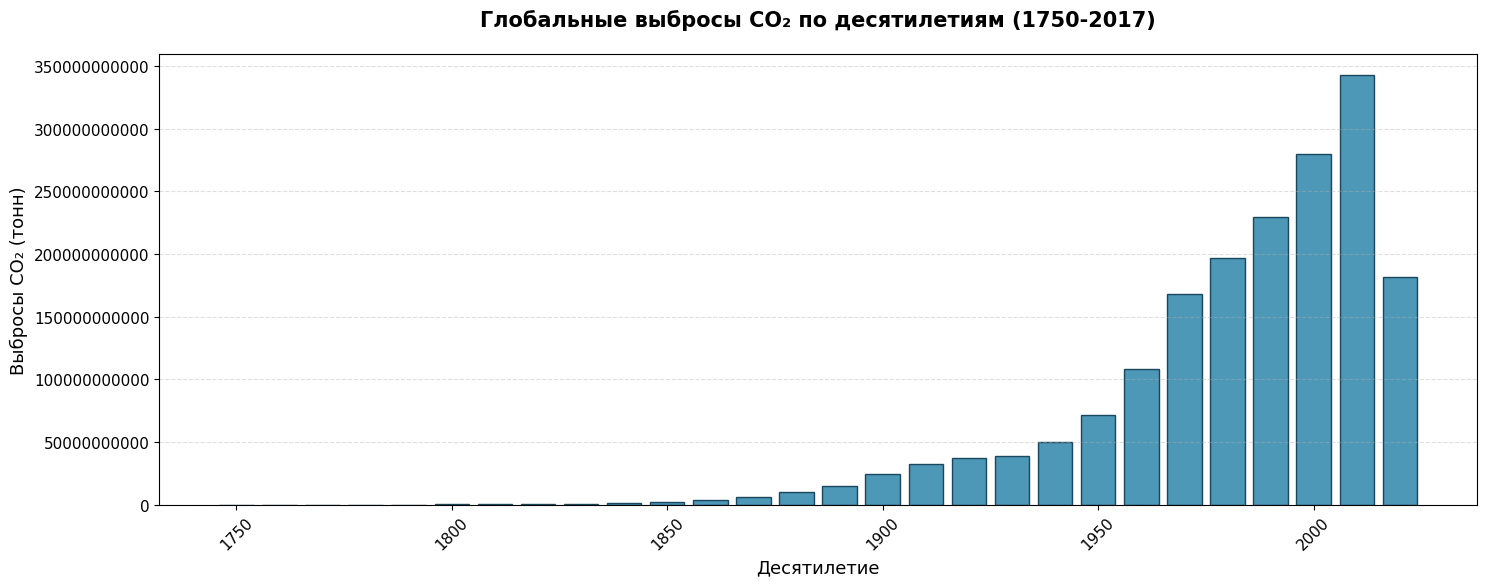

In [20]:
fig1, ax1 = plt.subplots(figsize=(15, 6))
ax1.bar(decade_totals.index, decade_totals.values, color='#2E86AB', edgecolor='#023047', alpha=0.85, width=8)
ax1.set_title('Глобальные выбросы CO₂ по десятилетиям (1750-2017)', fontsize=15, fontweight='bold', pad=20)
ax1.set_xlabel('Десятилетие', fontsize=13)
ax1.set_ylabel('Выбросы CO₂ (тонн)', fontsize=13)
ax1.tick_params(axis='x', rotation=45)
ax1.grid(axis='y', alpha=0.4, linestyle='--')
ax1.ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.savefig('график_1_десятилетия.png', dpi=300, bbox_inches='tight')
print(" Сохранён: график_1_десятилетия.png")
plt.show()

# Рейтинг стран-лидеров

Сохранён: график_2_страны_топ10.png


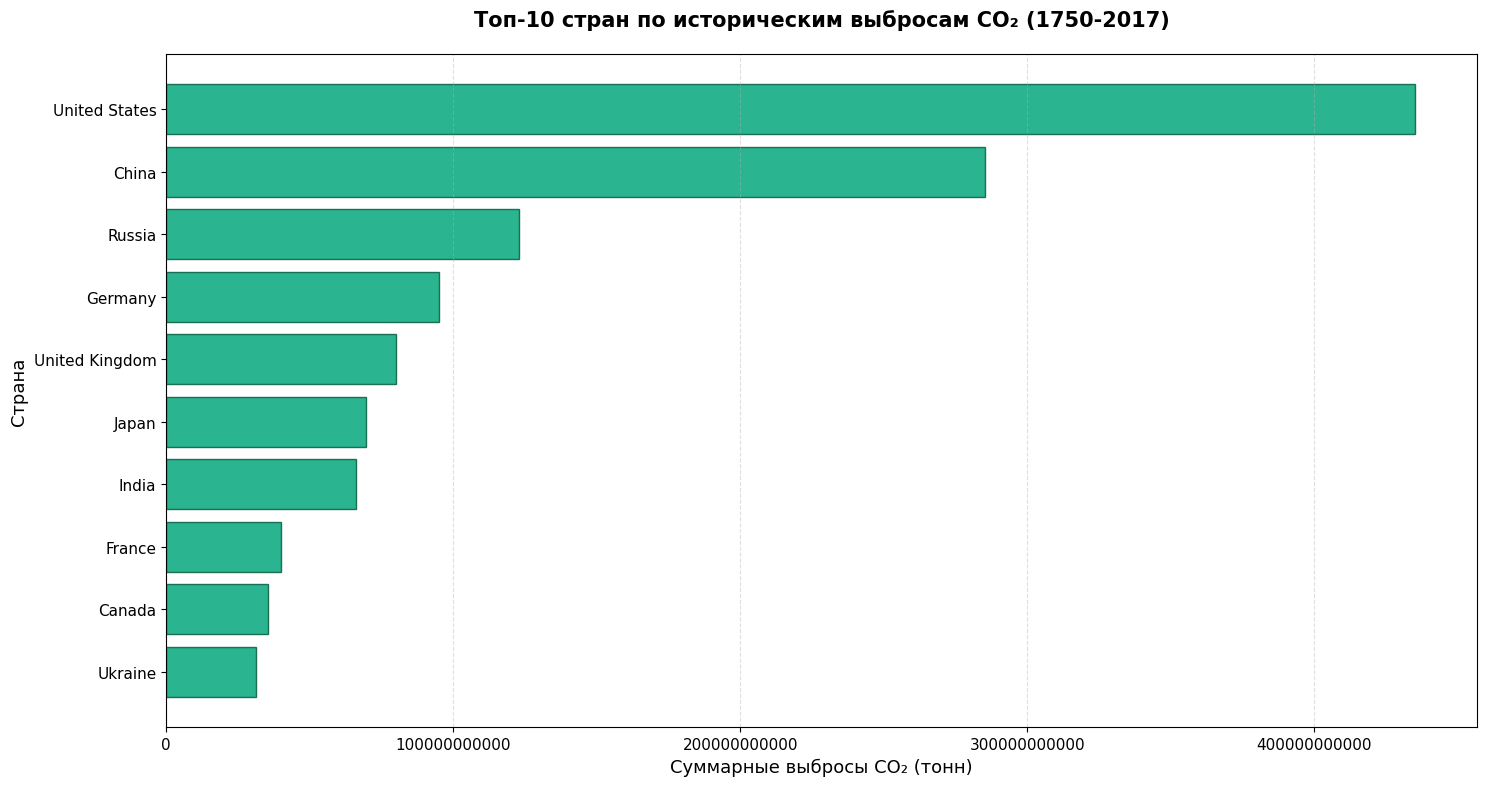

In [21]:
fig2, ax2 = plt.subplots(figsize=(15, 8))
top10_data = total_by_country.head(10)
bars = ax2.barh(range(len(top10_data)), top10_data.values, color='#06A77D', edgecolor='#035E3F', alpha=0.85)
ax2.set_yticks(range(len(top10_data)))
ax2.set_yticklabels(top10_data.index)
ax2.set_xlabel('Суммарные выбросы CO₂ (тонн)', fontsize=13)
ax2.set_ylabel('Страна', fontsize=13)
ax2.set_title('Топ-10 стран по историческим выбросам CO₂ (1750-2017)', fontsize=15, fontweight='bold', pad=20)
ax2.invert_yaxis()
ax2.grid(axis='x', alpha=0.4, linestyle='--')
ax2.ticklabel_format(style='plain', axis='x')
plt.tight_layout()
plt.savefig('график_2_страны_топ10.png', dpi=300, bbox_inches='tight')
print("Сохранён: график_2_страны_топ10.png")
plt.show()

# Эволюция выбросов топ-5 стран

 Сохранён: график_3_динамика_топ5.png


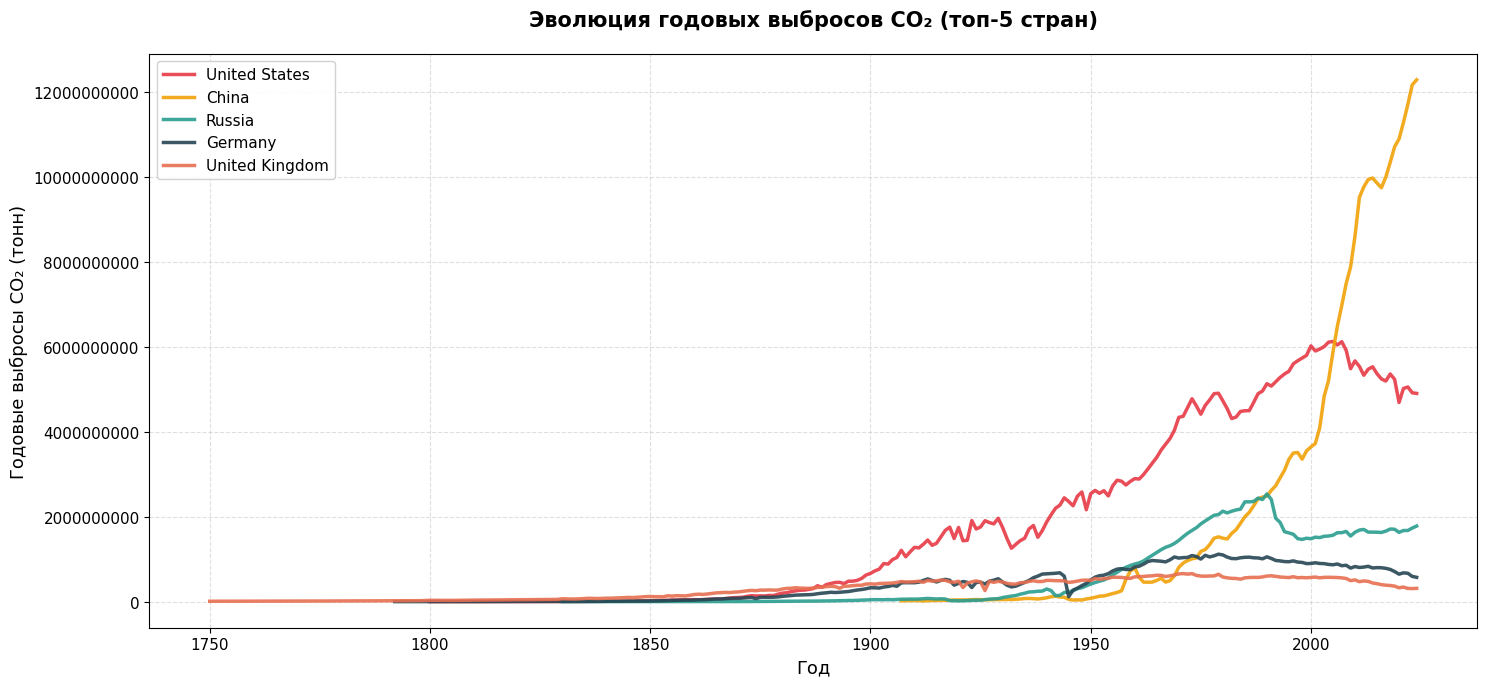

In [22]:
fig3, ax3 = plt.subplots(figsize=(15, 7))
top5_list = total_by_country.head(5).index
colors = ['#E63946', '#F1A208', '#2A9D8F', '#264653', '#E76F51']

for idx, country in enumerate(top5_list):
    country_series = clean_data[clean_data['Entity'] == country].sort_values('Year')
    ax3.plot(country_series['Year'], country_series['Annual CO₂ emissions'], 
             linewidth=2.5, label=country, alpha=0.9, color=colors[idx])

ax3.set_title('Эволюция годовых выбросов CO₂ (топ-5 стран)', fontsize=15, fontweight='bold', pad=20)
ax3.set_xlabel('Год', fontsize=13)
ax3.set_ylabel('Годовые выбросы CO₂ (тонн)', fontsize=13)
ax3.legend(loc='upper left', fontsize=11, framealpha=0.9)
ax3.grid(True, alpha=0.4, linestyle='--')
ax3.ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.savefig('график_3_динамика_топ5.png', dpi=300, bbox_inches='tight')
print(" Сохранён: график_3_динамика_топ5.png")
plt.show()

# Континентальное распределение

 Сохранён: график_4_континенты.png


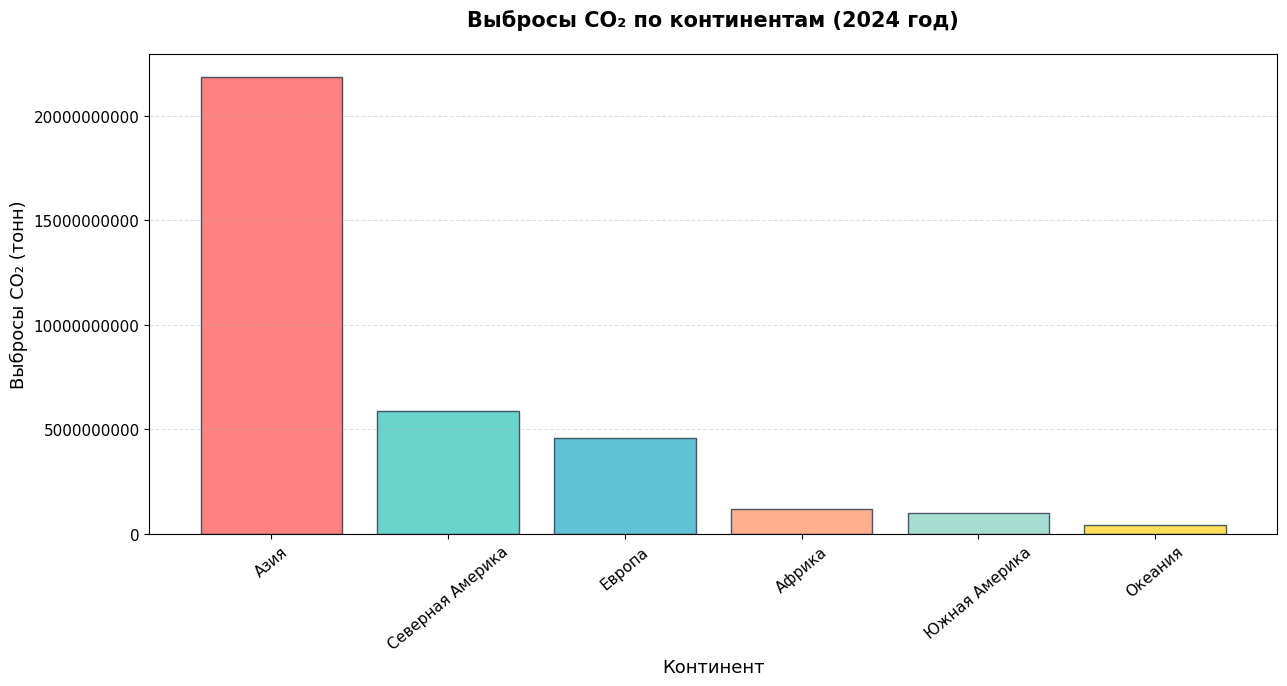

In [23]:
fig4, ax4 = plt.subplots(figsize=(13, 7))
palette = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#FFA07A', '#98D8C8', '#FFD93D']
bars = ax4.bar(continent_totals.index, continent_totals.values, color=palette[:len(continent_totals)], 
               edgecolor='#2C3E50', alpha=0.85)
ax4.set_title(f'Выбросы CO₂ по континентам ({int(last_year)} год)', fontsize=15, fontweight='bold', pad=20)
ax4.set_xlabel('Континент', fontsize=13)
ax4.set_ylabel('Выбросы CO₂ (тонн)', fontsize=13)
ax4.tick_params(axis='x', rotation=40)
ax4.grid(axis='y', alpha=0.4, linestyle='--')
ax4.ticklabel_format(style='plain', axis='y')
plt.tight_layout()
plt.savefig('график_4_континенты.png', dpi=300, bbox_inches='tight')
print(" Сохранён: график_4_континенты.png")
plt.show()

In [24]:
print(" ЛАБОРАТОРНАЯ РАБОТА №8 ЗАВЕРШЕНА УСПЕШНО!")

print("\n Созданные материалы:")
print("   • график_1_десятилетия.png")
print("   • график_2_страны_топ10.png")
print("   • график_3_динамика_топ5.png")
print("   • график_4_континенты.png")
print("\n Анализ данных о выбросах CO₂ выполнен полностью.")


 ЛАБОРАТОРНАЯ РАБОТА №8 ЗАВЕРШЕНА УСПЕШНО!

 Созданные материалы:
   • график_1_десятилетия.png
   • график_2_страны_топ10.png
   • график_3_динамика_топ5.png
   • график_4_континенты.png

 Анализ данных о выбросах CO₂ выполнен полностью.
